# Files, Directories & Permissions

Servers, containers, cloud machines and most data platforms run **Linux**. You work with them through a **shell** (usually `bash`) and the file system. This lesson covers how Linux organises files, how permissions control access, and how to find and measure files.

**After this lesson you can:**

1. Navigate the file-system hierarchy with `pwd`, `ls`, `cd`, `mkdir`, `cp`, `mv`, `rm`.
2. Read and change permissions (`chmod`, octal notation, `umask`).
3. Explain inodes, hard links and symbolic links.
4. Find files with `find` and measure disk usage with `du` and `df`.

The notebook runs real shell commands through a small Python helper, `sh()`. On Windows, use **WSL** (Windows Subsystem for Linux) to follow along.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. The File-System Hierarchy

Linux has one tree that starts at `/` (the **root**). Disks and network shares are attached ("mounted") somewhere in this tree.

| Path | Content |
| :--- | :--- |
| `/home/<user>` | personal files (`~` is a shortcut) |
| `/etc` | system configuration files |
| `/var/log` | log files |
| `/tmp` | temporary files, deleted on reboot |
| `/usr/bin`, `/usr/local/bin` | installed programs |
| `/proc`, `/sys` | virtual files that show kernel and process information |
| `/mnt`, `/media` | mounted drives (in WSL, `/mnt/c` is the Windows C: drive) |

A path that starts with `/` is **absolute**; any other path is **relative** to the current directory. `.` is the current directory, `..` the parent.

In [2]:
sh("pwd && ls -d /etc /home /tmp /usr /var /proc /mnt")
sh("mkdir -p project/{data/raw,data/clean,src,docs} && touch project/src/main.py project/docs/notes.md")
sh("ls -R project")
sh("cp project/src/main.py project/src/backup.py && mv project/docs/notes.md project/README.md && ls project project/src")
sh("rm project/src/backup.py && rmdir project/docs && ls project")

$ pwd && ls -d /etc /home /tmp /usr /var /proc /mnt
<work>
/etc
/home
/mnt
/proc
/tmp
/usr
/var
$ mkdir -p project/{data/raw,data/clean,src,docs} && touch project/src/main.py project/docs/notes.md
$ ls -R project
project:
data
docs
src

project/data:
clean
raw

project/data/clean:

project/data/raw:

project/docs:
notes.md

project/src:
main.py
$ cp project/src/main.py project/src/backup.py && mv project/docs/notes.md project/README.md && ls project project/src
project:
README.md
data
docs
src

project/src:
backup.py
main.py
$ rm project/src/backup.py && rmdir project/docs && ls project
README.md
data
src


`rm` deletes permanently: there is no recycle bin. `rm -r` deletes a whole folder tree. Check the path twice before you run it.

## 2. Permissions

`ls -l` shows the permissions of each file as 10 characters: the file type, then three groups of `rwx` for the **owner**, the **group** and **others**.

```
-rwxr-x---  1 ayse data  512 Jun 1 09:00 train.sh
│└┬┘└┬┘└┬┘
│ │  │  └── others: no access
│ │  └───── group "data": read + execute
│ └──────── owner "ayse": read + write + execute
└────────── type: - file, d directory, l link
```

In **octal notation**, each group is one digit: read = 4, write = 2, execute = 1. So `rwxr-x---` = 7 5 0 = `750`.

In [3]:
(WORK / "train.sh").write_text("#!/bin/bash\necho training...\n")
(WORK / "secrets.env").write_text("DB_PASSWORD=change-me\n")
sh("ls -l train.sh secrets.env")
sh("./train.sh")                             # fails: no execute permission
sh("chmod u+x train.sh && ./train.sh")       # symbolic mode: add execute for the user
sh("chmod 600 secrets.env && chmod 750 train.sh && ls -l train.sh secrets.env")
sh("stat -c '%n  octal=%a  owner=%U  group=%G  size=%s bytes' train.sh secrets.env")
sh("umask && touch new_file && mkdir new_dir && ls -ld new_file new_dir")

$ ls -l train.sh secrets.env
-rw-r--r-- 1 root root 22 Nov 16 17:00 secrets.env
-rw-r--r-- 1 root root 29 Nov 16 17:00 train.sh
$ ./train.sh
bash: line 1: ./train.sh: Permission denied
$ chmod u+x train.sh && ./train.sh
training...
$ chmod 600 secrets.env && chmod 750 train.sh && ls -l train.sh secrets.env
-rw------- 1 root root 22 Nov 16 17:00 secrets.env
-rwxr-x--- 1 root root 29 Nov 16 17:00 train.sh
$ stat -c '%n  octal=%a  owner=%U  group=%G  size=%s bytes' train.sh secrets.env
train.sh  octal=750  owner=root  group=root  size=29 bytes
secrets.env  octal=600  owner=root  group=root  size=22 bytes
$ umask && touch new_file && mkdir new_dir && ls -ld new_file new_dir
0022
drwxr-xr-x 2 root root 4096 Nov 16 17:00 new_dir
-rw-r--r-- 1 root root    0 Nov 16 17:00 new_file


`umask` removes permissions from new files. With the common umask `0022`, new files get `644` (`rw-r--r--`) and new directories `755`.

Typical values: `600` for secrets and SSH keys, `644` for normal files, `755` for scripts and directories. Never use `777`: it lets every user change the file.

## 3. Inodes and Links

A file's data and metadata (size, owner, permissions, timestamps) live in an **inode**. A file name is only a directory entry that points to an inode.

- A **hard link** is a second name for the same inode. The data stays until the last name is removed.
- A **symbolic link** (symlink) is a small file that contains a path to another name. It breaks if the target moves.

In [4]:
(WORK / "model_v3.bin").write_text("weights" * 100)
sh("ln model_v3.bin model_hardlink.bin && ln -s model_v3.bin model_latest.bin")
sh("ls -li model_*")                         # first column: the inode number
sh("rm model_v3.bin && cat model_hardlink.bin | head -c 21; echo; cat model_latest.bin")

$ ln model_v3.bin model_hardlink.bin && ln -s model_v3.bin model_latest.bin
$ ls -li model_*
1830282 -rw-r--r-- 2 root root 700 Nov 16 17:00 model_hardlink.bin
1830283 lrwxrwxrwx 1 root root  12 Nov 16 17:00 model_latest.bin -> model_v3.bin
1830282 -rw-r--r-- 2 root root 700 Nov 16 17:00 model_v3.bin
$ rm model_v3.bin && cat model_hardlink.bin | head -c 21; echo; cat model_latest.bin
weightsweightsweights
cat: model_latest.bin: No such file or directory


The hard link has the same inode number as the original and still works after the original name is deleted. The symlink now points to a missing name ("No such file or directory"). Deployment tools use symlinks to switch versions atomically: `current -> releases/2025-06-01`.

## 4. Find Files and Measure Disk Usage

- `find PATH -name '*.ipynb' -size +1M -mtime -7` finds files by name, size and age.
- `du -sh folder` shows the disk space a folder uses; `df -h` shows free space per file system.

The cell measures the **real** module folders of this course.

In [5]:
sh(f"find {REPO}/M[0-9][0-9]-* -maxdepth 1 -name '*.ipynb' | wc -l")
sh(f"find {REPO}/M[0-9][0-9]-* -maxdepth 1 -name '*.ipynb' -size +2M | head -5")
sh("df -h / /tmp | head -3")
sizes_raw = sh(f"du -sk {REPO}/M[0-9][0-9]-*/ | sort -k2", quiet=True)

$ find <repo>/M[0-9][0-9]-* -maxdepth 1 -name '*.ipynb' | wc -l
410


$ find <repo>/M[0-9][0-9]-* -maxdepth 1 -name '*.ipynb' -size +2M | head -5
<repo>/M22-Generative Models/06-Diffusion Models I - The Math.ipynb
<repo>/M22-Generative Models/12-Generative Evaluation.ipynb
$ df -h / /tmp | head -3
Filesystem      Size  Used Avail Use% Mounted on
/dev/sdd       1007G  237G  720G  25% /
/dev/sdd       1007G  237G  720G  25% /


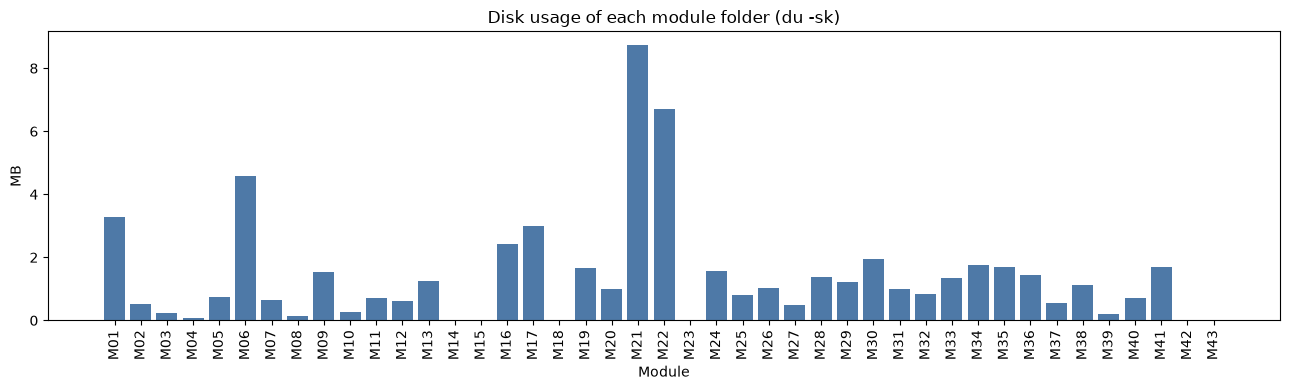

largest folders: M21 8.7 MB, M22 6.7 MB, M06 4.6 MB


In [6]:
import matplotlib.pyplot as plt

rows = []
for line in sizes_raw.splitlines():
    kb, path = line.split("\t")
    rows.append((Path(path).name[:3], int(kb) / 1024))

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar([r[0] for r in rows], [r[1] for r in rows], color="#4E79A7")
ax.set(title="Disk usage of each module folder (du -sk)", xlabel="Module", ylabel="MB")
ax.tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()
top = sorted(rows, key=lambda r: -r[1])[:3]
print("largest folders:", ", ".join(f"{m} {mb:.1f} MB" for m, mb in top))

Notebooks store their outputs, including images, inside the `.ipynb` file. Modules with many plots therefore use more disk space.

*Insight: Use the principle of least privilege: give files and users only the permissions they need (`600` for secrets, `755` for scripts). Many security incidents start with a world-readable key file or a world-writable script.*

## Real-World Use Case or Analogy

The Linux file system is like an **office building with keys**. The tree is the floor plan (`/home` is the employees' floor, `/etc` the building management office). Permissions are the locks on each door: the owner has a full key, the department (group) can enter some rooms, visitors (others) see only the lobby.

When a data pipeline fails on a server with "Permission denied", the cause is almost always one of these locks: the service user cannot read the input folder, or cannot write the output folder. `ls -l`, `stat` and `chmod` find and fix it.